<a href="https://colab.research.google.com/github/1322vishav/Image-Processing/blob/main/Assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import math
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_PATH = '/content/drive/MyDrive/image.jpg'

gray = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError(f"Could not read {IMG_PATH}")

def to_u8(a):
    return np.clip(a, 0, 255).astype(np.uint8)

shape = gray.shape
print("Image shape:", shape)

Mounted at /content/drive
Image shape: (720, 1280)


In [2]:
ua, ub = -40, 40
gm, gs = 0, 20
ea = 0.05
la, lb = 0.2, 3
ra, rb = 0, 800

rng = np.random.default_rng(1)

def U():
    return 1 - rng.random(shape)

def uniform_noise():
    return ua + (ub - ua) * rng.random(shape)

def gaussian_noise():
    return gm + gs * np.sqrt(-2 * np.log(U())) * np.cos(2 * np.pi * rng.random(shape))

def exponential_noise():
    return -np.log(U()) / ea

def erlang_noise():
    return sum(-np.log(U()) / la for _ in range(lb))

def rayleigh_noise():
    return ra + np.sqrt(-rb * np.log(U()))

In [3]:
rng2 = np.random.default_rng(2)

noises = {
    'Uniform': dict(
        mine=uniform_noise(),
        ref=rng2.uniform(ua, ub, shape),
        pdf=lambda z: np.where((z >= ua) & (z <= ub), 1 / (ub - ua), 0),
        mean=(ua + ub) / 2,
        var=(ub - ua) ** 2 / 12),
    'Gaussian': dict(
        mine=gaussian_noise(),
        ref=rng2.normal(gm, gs, shape),
        pdf=lambda z: np.exp(-(z - gm) ** 2 / (2 * gs ** 2)) / (gs * np.sqrt(2 * np.pi)),
        mean=gm,
        var=gs ** 2),
    'Erlang': dict(
        mine=erlang_noise(),
        ref=rng2.gamma(lb, 1 / la, shape),
        pdf=lambda z: np.where(z >= 0, la ** lb * np.abs(z) ** (lb - 1) * np.exp(-la * z) / math.factorial(lb - 1), 0),
        mean=lb / la,
        var=lb / la ** 2),
    'Exponential': dict(
        mine=exponential_noise(),
        ref=rng2.exponential(1 / ea, shape),
        pdf=lambda z: np.where(z >= 0, ea * np.exp(-ea * z), 0),
        mean=1 / ea,
        var=1 / ea ** 2),
    'Rayleigh': dict(
        mine=rayleigh_noise(),
        ref=ra + rng2.rayleigh(np.sqrt(rb / 2), shape),
        pdf=lambda z: np.where(z >= ra, (2 / rb) * (z - ra) * np.exp(-(z - ra) ** 2 / rb), 0),
        mean=ra + np.sqrt(np.pi * rb / 4),
        var=rb * (4 - np.pi) / 4),
}

print(f"{'Noise':<12}{'mean(mine)':>11}{'mean(np)':>10}{'mean(th)':>10}{'var(mine)':>11}{'var(np)':>10}{'var(th)':>10}")
for name, d in noises.items():
    print(f"{name:<12}{d['mine'].mean():11.2f}{d['ref'].mean():10.2f}{d['mean']:10.2f}"
          f"{d['mine'].var():11.1f}{d['ref'].var():10.1f}{d['var']:10.1f}")

Noise        mean(mine)  mean(np)  mean(th)  var(mine)   var(np)   var(th)
Uniform            0.00      0.01      0.00      533.4     533.2     533.3
Gaussian          -0.03      0.02      0.00      399.8     399.6     400.0
Erlang            15.01     15.02     15.00       74.9      75.1      75.0
Exponential       19.97     20.06     20.00      399.5     402.5     400.0
Rayleigh          25.06     25.08     25.07      171.9     172.1     171.7


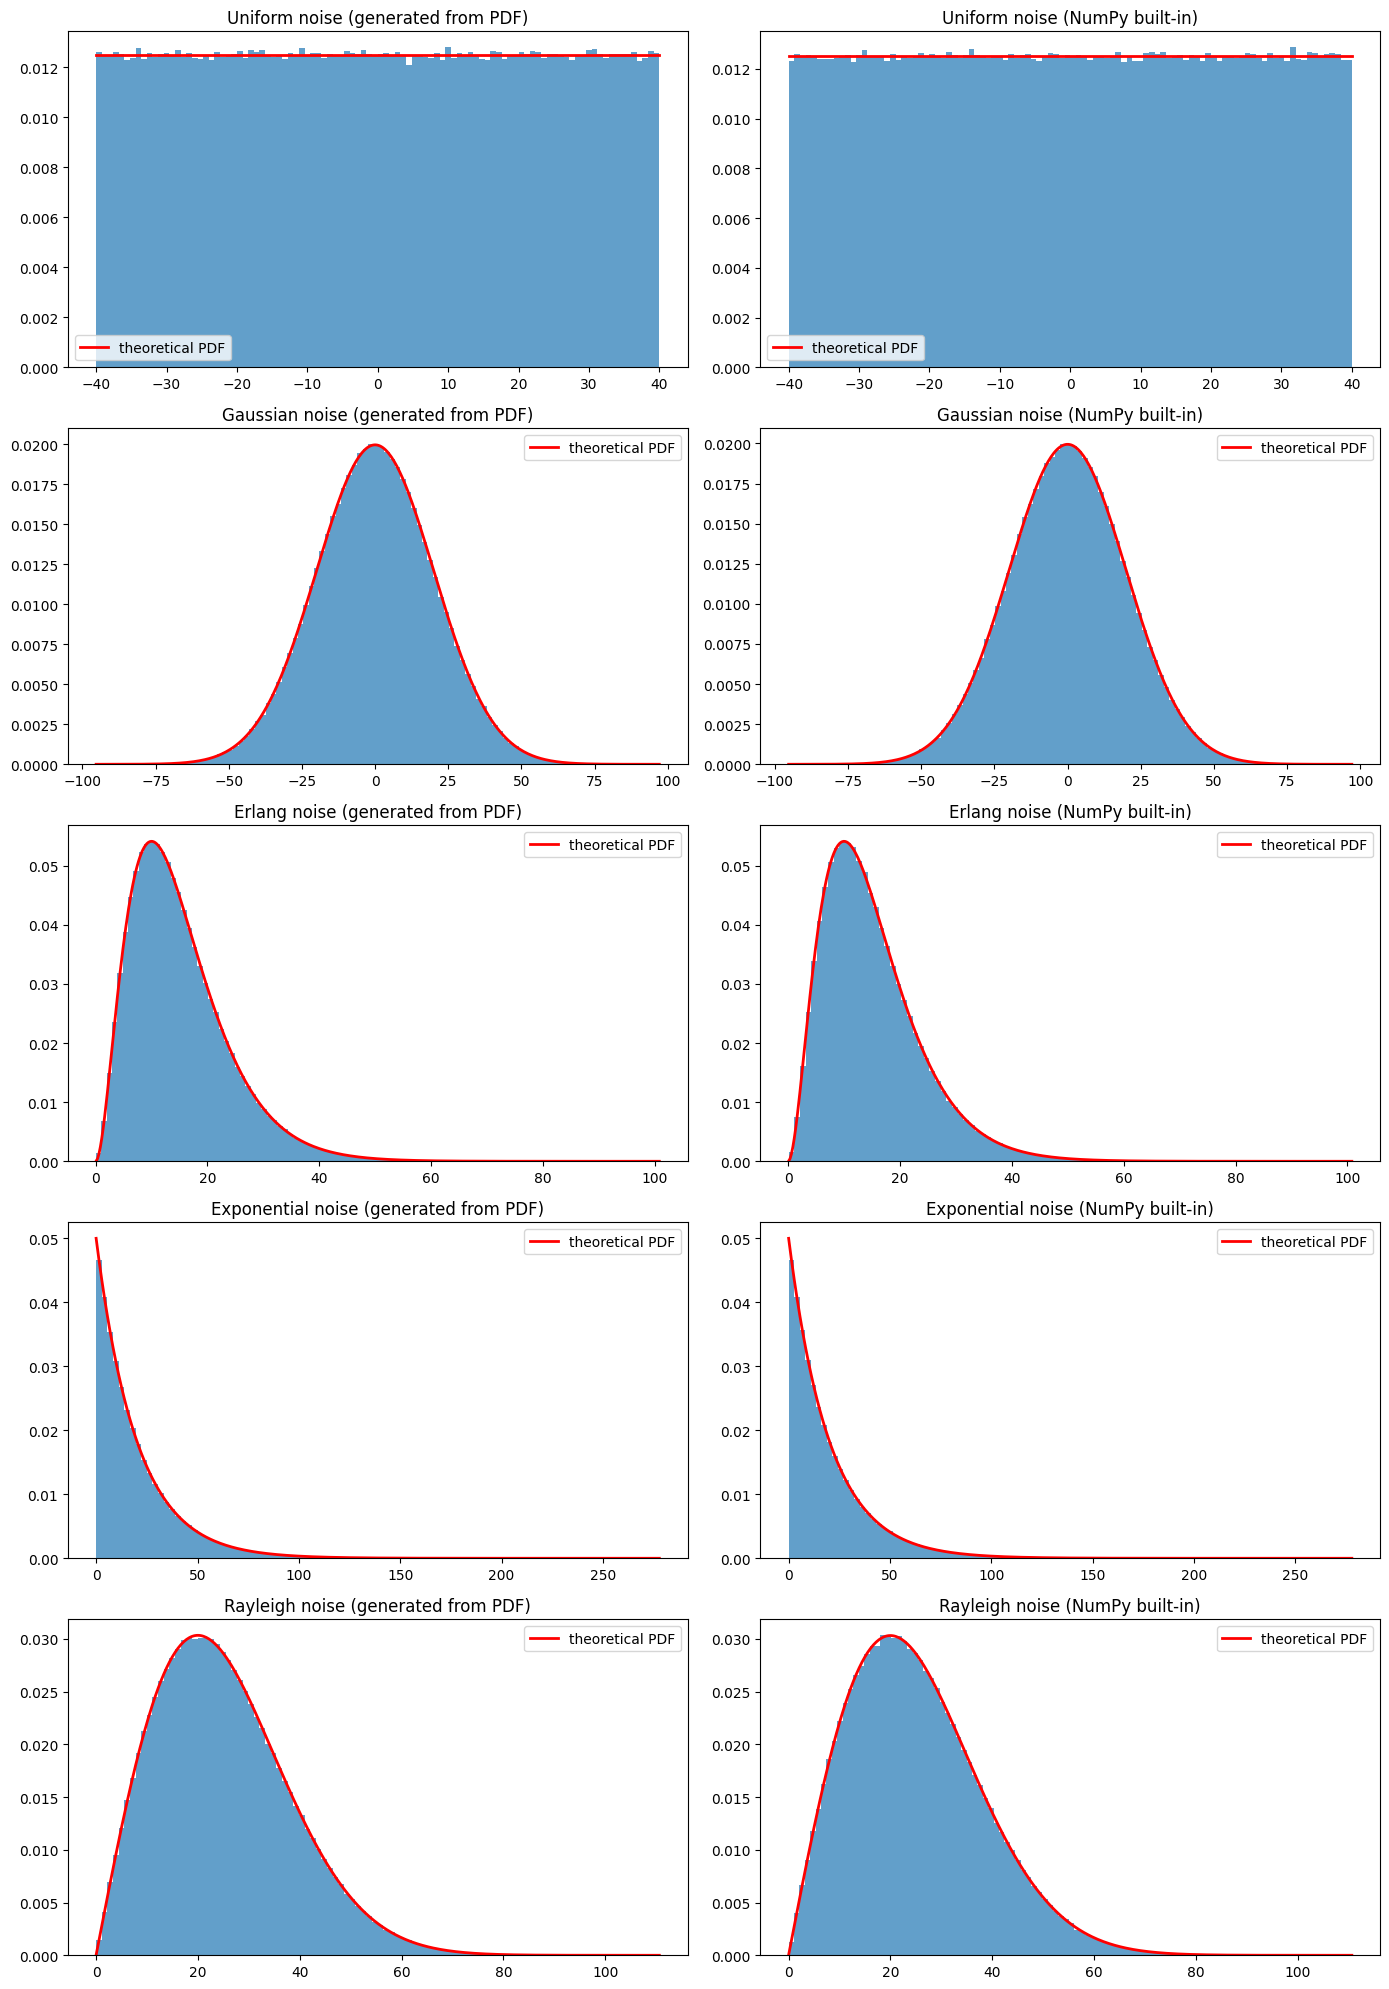

In [4]:
fig, ax = plt.subplots(5, 2, figsize=(14, 20))

for r, (name, d) in enumerate(noises.items()):
    lo = min(d['mine'].min(), d['ref'].min())
    hi = max(d['mine'].max(), d['ref'].max())
    z = np.linspace(lo, hi, 400)

    ax[r, 0].hist(d['mine'].ravel(), bins=100, density=True, alpha=0.7)
    ax[r, 0].plot(z, d['pdf'](z), 'r', lw=2, label='theoretical PDF')
    ax[r, 0].set_title(f'{name} noise (generated from PDF)')
    ax[r, 0].legend()

    ax[r, 1].hist(d['ref'].ravel(), bins=100, density=True, alpha=0.7)
    ax[r, 1].plot(z, d['pdf'](z), 'r', lw=2, label='theoretical PDF')
    ax[r, 1].set_title(f'{name} noise (NumPy built-in)')
    ax[r, 1].legend()

plt.tight_layout()
plt.show()

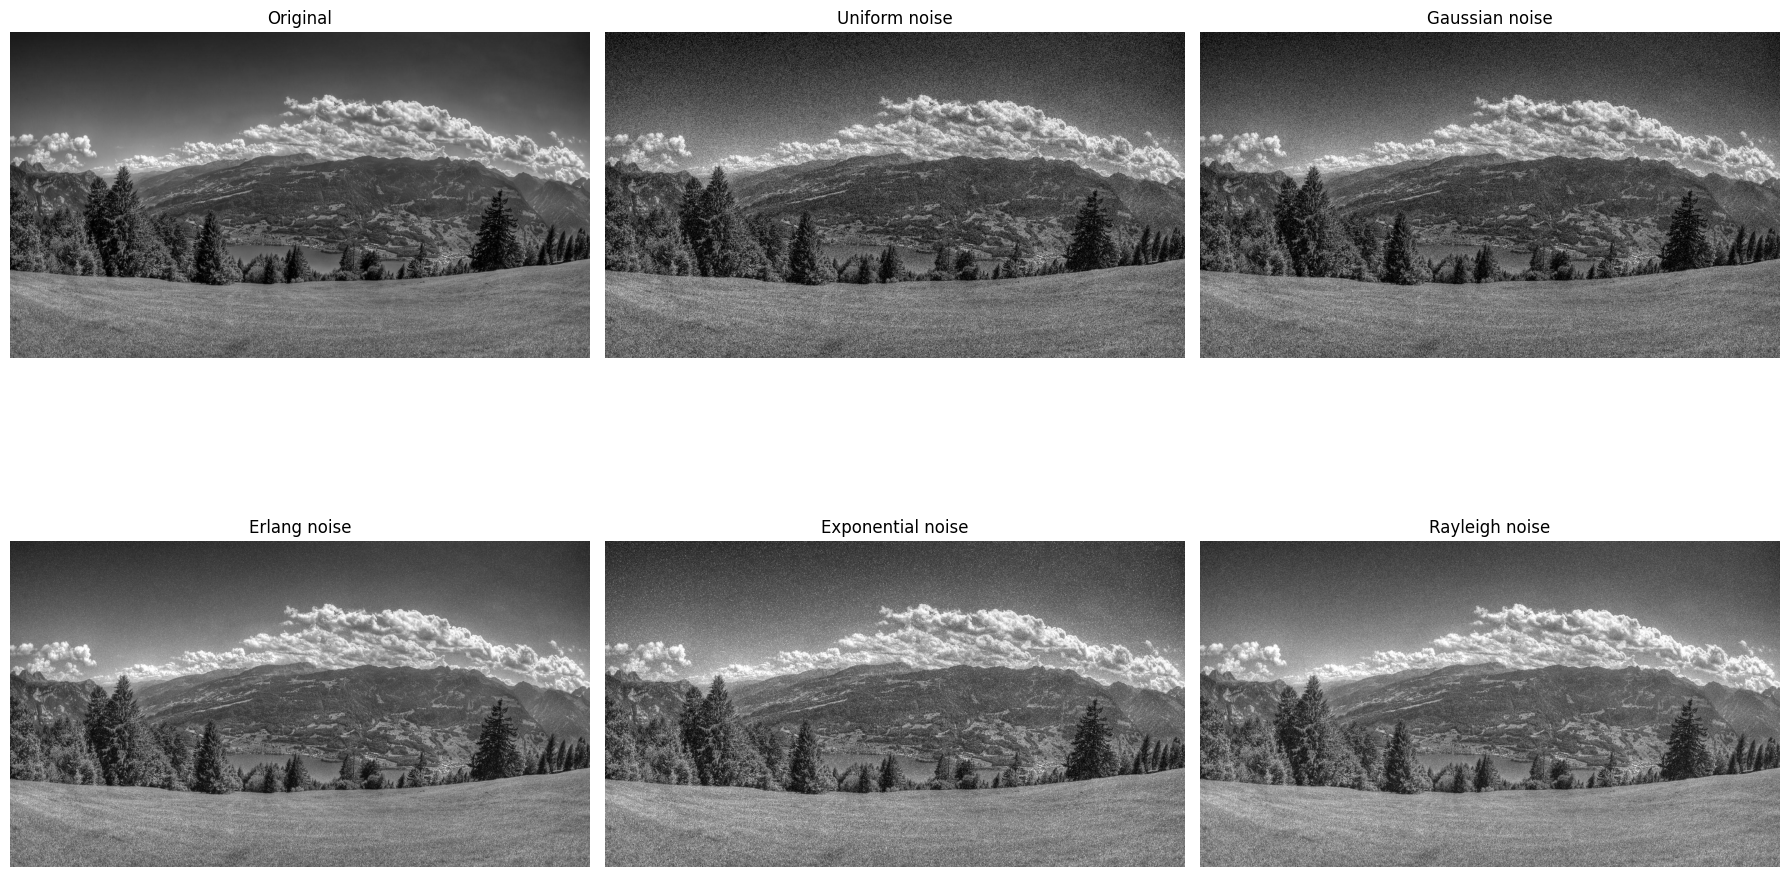

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(18, 12))

ax[0, 0].imshow(gray, cmap='gray', vmin=0, vmax=255)
ax[0, 0].set_title('Original')

for a, (name, d) in zip(ax.ravel()[1:], noises.items()):
    a.imshow(to_u8(gray + d['mine']), cmap='gray', vmin=0, vmax=255)
    a.set_title(f'{name} noise')

for a in ax.ravel():
    a.axis('off')

plt.tight_layout()
plt.show()